# Customer-level RFM Output with Quality Assertions (RFM Validation)

Task: build the customer-level RFM table from the cleaned Online Retail II data and add quality assertions,
so the RFM output is checked before anyone uses it.

**Input:** `online_retail_II_cleaned.csv` (output of the Data Cleaning notebook, unzip `online_retail_II_cleaned.zip` first)

**Steps:** load cleaned data → load into PostgreSQL → RFM SQL query → segments → quality assertions → prove the checks work → save files

## 1. Import libraries and load the cleaned data

In [1]:
import os
import io
import pandas as pd
import matplotlib.pyplot as plt
import psycopg2
from sqlalchemy import create_engine, text

In [2]:
df = pd.read_csv('online_retail_II_cleaned.csv', dtype={'Invoice': str, 'StockCode': str}, parse_dates=['InvoiceDate'])
df['CustomerID'] = df['CustomerID'].astype('Int64')

print('Rows:', len(df))
print('Customers:', df['CustomerID'].nunique())
print('Rows without CustomerID (guest sales):', df['CustomerID'].isnull().sum())
df.head()

Rows: 1003338
Customers: 5852
Rows without CustomerID (guest sales): 226761


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,Revenue,Month,Day,Hour
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4,2009-12,Tuesday,7
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009-12,Tuesday,7
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009-12,Tuesday,7
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8,2009-12,Tuesday,7
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0,2009-12,Tuesday,7


RFM is calculated per customer, so only rows **with** a CustomerID are used.

In [3]:
customers = df.dropna(subset=['CustomerID'])
print('Rows used for RFM:', len(customers))

Rows used for RFM: 776577


## 2. Load the cleaned data into PostgreSQL

Change the details below to match your PostgreSQL installation.
Libraries needed (install once): `pip install pandas matplotlib sqlalchemy psycopg2-binary`

In [4]:
DB_HOST = 'localhost'
DB_PORT = 5432
DB_USER = 'postgres'
DB_PASSWORD = os.environ.get('PG_PASSWORD', 'postgres')   # put your PostgreSQL password here
DB_NAME = 'online_retail'

In [5]:
# create the database if it is not there
conn = psycopg2.connect(host=DB_HOST, port=DB_PORT, user=DB_USER, password=DB_PASSWORD, dbname='postgres')
conn.autocommit = True
cur = conn.cursor()
cur.execute('SELECT 1 FROM pg_database WHERE datname = %s', (DB_NAME,))
if cur.fetchone() is None:
    cur.execute(f'CREATE DATABASE {DB_NAME}')
    print('Database created:', DB_NAME)
else:
    print('Database already exists:', DB_NAME)
conn.close()

engine = create_engine(f'postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}')

Database already exists: online_retail


In [6]:
create_table = '''
DROP TABLE IF EXISTS clean_sales;
CREATE TABLE clean_sales (
    invoice       VARCHAR(10),
    stock_code    VARCHAR(20),
    description   TEXT,
    quantity      INTEGER,
    invoice_date  TIMESTAMP,
    price         NUMERIC(12,2),
    customer_id   INTEGER,
    country       VARCHAR(50),
    revenue       NUMERIC(14,2)
);
'''
with engine.begin() as con:
    con.execute(text(create_table))

columns = ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'Country', 'Revenue']
buffer = io.StringIO()
df[columns].to_csv(buffer, index=False, header=False)
buffer.seek(0)

conn = psycopg2.connect(host=DB_HOST, port=DB_PORT, user=DB_USER, password=DB_PASSWORD, dbname=DB_NAME)
cur = conn.cursor()
cur.copy_expert('COPY clean_sales FROM STDIN WITH (FORMAT csv)', buffer)
conn.commit()
conn.close()

with engine.connect() as con:
    pg_rows = con.execute(text('SELECT COUNT(*) FROM clean_sales')).scalar()
print('Rows in PostgreSQL clean_sales:', pg_rows)
assert pg_rows == len(df), 'PostgreSQL row count does not match the CSV'

Rows in PostgreSQL clean_sales: 1003338


## 3. RFM query (customer-level output)

- **Recency**: days since the customer's last purchase, counted from the **snapshot date** (the day after the last invoice = 10-Dec-2011). Smaller is better.
- **Frequency**: number of orders (distinct invoices). Bigger is better.
- **Monetary**: total money spent. Bigger is better.

Each value gets a **score from 1 to 5** with `NTILE(5)` (5 equal-size groups, 5 = best).
`customer_id` is added to the `ORDER BY` so the scores are the same every time the query runs.

In [7]:
rfm_query = '''
WITH snapshot AS (
    SELECT MAX(invoice_date)::date + 1 AS snapshot_date
    FROM clean_sales
),
rfm_base AS (
    SELECT customer_id,
           MAX(invoice_date)                                              AS last_purchase,
           (SELECT snapshot_date FROM snapshot) - MAX(invoice_date)::date AS recency_days,
           COUNT(DISTINCT invoice)                                        AS frequency,
           ROUND(SUM(revenue), 2)                                         AS monetary
    FROM clean_sales
    WHERE customer_id IS NOT NULL
    GROUP BY customer_id
),
rfm_scores AS (
    SELECT *,
           NTILE(5) OVER (ORDER BY recency_days DESC, customer_id) AS r_score,
           NTILE(5) OVER (ORDER BY frequency, customer_id)         AS f_score,
           NTILE(5) OVER (ORDER BY monetary, customer_id)          AS m_score
    FROM rfm_base
)
SELECT customer_id, last_purchase, recency_days, frequency, monetary,
       r_score, f_score, m_score,
       CONCAT(r_score, f_score, m_score) AS rfm_score,
       r_score + f_score + m_score       AS rfm_total,
       CASE
           WHEN r_score >= 4 AND f_score >= 4 THEN 'Champions'
           WHEN r_score >= 3 AND f_score >= 3 THEN 'Loyal Customers'
           WHEN r_score >= 4 AND f_score <= 2 THEN 'New / Promising'
           WHEN r_score = 3  AND f_score <= 2 THEN 'Need Attention'
           WHEN r_score <= 2 AND f_score >= 3 THEN 'At Risk'
           WHEN r_score <= 2 AND f_score <= 2 THEN 'Lost / Hibernating'
           ELSE 'Unclassified'
       END AS segment
FROM rfm_scores
ORDER BY customer_id;
'''
rfm = pd.read_sql(text(rfm_query), engine)
rfm['monetary'] = rfm['monetary'].astype(float)
print('RFM rows:', len(rfm))
rfm.head(10)

RFM rows: 5852


,customer_id,last_purchase,recency_days,frequency,monetary,r_score,f_score,m_score,rfm_score,rfm_total,segment
0,12346,2010-06-28 13:53:00,530,2,169.36,1,2,1,121,4,Lost / Hibernating
1,12347,2011-12-07 15:52:00,3,8,4921.53,5,4,5,545,14,Champions
2,12348,2011-09-25 13:13:00,76,5,1658.40,3,4,4,344,11,Loyal Customers
3,12349,2011-11-21 09:51:00,19,3,3678.69,5,3,5,535,13,Loyal Customers
4,12350,2011-02-02 16:01:00,311,1,294.40,2,1,2,212,5,Lost / Hibernating
5,12351,2010-11-29 15:23:00,376,1,300.93,2,1,2,212,5,Lost / Hibernating
6,12352,2011-11-03 14:37:00,37,9,1729.54,4,5,4,454,13,Champions
7,12353,2011-05-19 17:47:00,205,2,406.76,2,2,2,222,6,Lost / Hibernating
8,12354,2011-04-21 13:11:00,233,1,1079.40,2,1,3,213,6,Lost / Hibernating
9,12355,2011-05-09 13:49:00,215,2,947.61,2,2,3,223,7,Lost / Hibernating


**Segment rules** (based on the R and F scores):

| Segment | Rule | Meaning |
|---|---|---|
| Champions | R ≥ 4 and F ≥ 4 | Bought recently and often |
| Loyal Customers | R ≥ 3 and F ≥ 3 | Buy regularly |
| New / Promising | R ≥ 4 and F ≤ 2 | Bought recently, but only a few times |
| Need Attention | R = 3 and F ≤ 2 | Average recency, few orders |
| At Risk | R ≤ 2 and F ≥ 3 | Used to buy often, but not for a long time |
| Lost / Hibernating | R ≤ 2 and F ≤ 2 | Few orders and not for a long time |

In [8]:
segments = rfm.groupby('segment').agg(customers=('customer_id', 'count'),
                                      revenue=('monetary', 'sum'),
                                      avg_recency_days=('recency_days', 'mean'),
                                      avg_orders=('frequency', 'mean'),
                                      avg_spend=('monetary', 'mean'))
segments['% customers'] = (segments['customers'] / segments['customers'].sum() * 100).round(1)
segments['% revenue'] = (segments['revenue'] / segments['revenue'].sum() * 100).round(1)
segments = segments.sort_values('revenue', ascending=False).round(2)
segments

,customers,revenue,avg_recency_days,avg_orders,avg_spend,% customers,% revenue
segment,,,,,,,
Champions,1463,11768114.50,20.54,15.60,8043.82,25.0,70.0
Loyal Customers,1218,2465370.41,78.34,5.39,2024.11,20.8,14.7
At Risk,829,1520075.55,368.17,4.99,1833.63,14.2,9.0
Lost / Hibernating,1513,620995.43,456.82,1.25,410.44,25.9,3.7
New / Promising,445,242803.87,28.39,1.47,545.63,7.6,1.4
Need Attention,384,205569.76,105.77,1.36,535.34,6.6,1.2


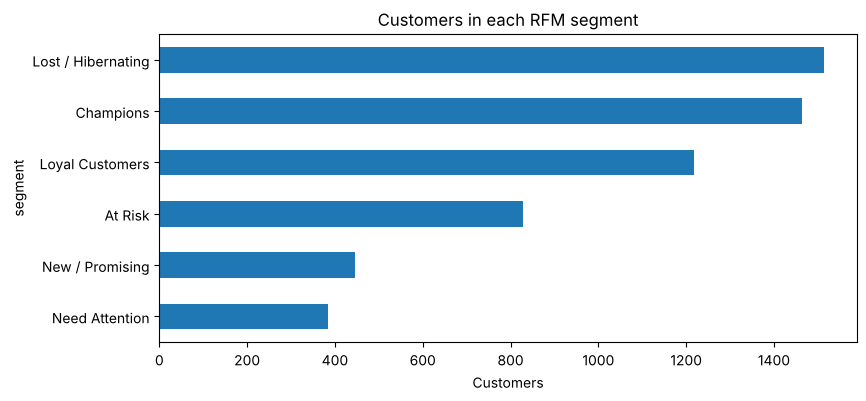

In [9]:
segments['customers'].sort_values().plot(kind='barh', figsize=(9, 4))
plt.title('Customers in each RFM segment')
plt.xlabel('Customers')
plt.show()

## 4. RFM validation: quality assertions

The RFM table must pass all these checks before it is used:

| Group | What is checked |
|---|---|
| 1. Completeness and uniqueness | One row per customer, no customer lost or added, no empty values |
| 2. Valid ranges | Recency, frequency, monetary and scores are inside their allowed ranges |
| 3. Score logic | A better value never gets a worse score, and each score group has 20% of customers |
| 4. Segment logic | Every customer has exactly one segment and it follows its rule |
| 5. Reconciliation | SQL values are recalculated in pandas and must be the same; totals must match the clean data |

Note: `NTILE(5)` makes equal-size groups, so customers with the same value (for example the many customers with only 1 order)
can fall into two neighbouring score groups. The score logic checks allow this, but they fail if a **better** value ever gets a **lower** score.

### 4.1 Recalculate R, F and M in pandas (independent of SQL)

In [10]:
snapshot_date = df['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)
data_days = (snapshot_date - df['InvoiceDate'].min().normalize()).days

rfm_pandas = customers.groupby('CustomerID').agg(last_purchase=('InvoiceDate', 'max'),
                                                 frequency=('Invoice', 'nunique'),
                                                 monetary=('Revenue', 'sum'))
rfm_pandas['recency_days'] = (snapshot_date - rfm_pandas['last_purchase'].dt.normalize()).dt.days
rfm_pandas.index = rfm_pandas.index.astype(int)

orders_per_customer = customers.groupby('CustomerID')['Invoice'].nunique()

print('Snapshot date:', snapshot_date.date())
print('Data period (days):', data_days)
print('Customers in pandas:', len(rfm_pandas))

Snapshot date: 2011-12-10
Data period (days): 739
Customers in pandas: 5852


### 4.2 The quality assertions

In [11]:
def segment_rule(r, f):
    if r >= 4 and f >= 4: return 'Champions'
    if r >= 3 and f >= 3: return 'Loyal Customers'
    if r >= 4 and f <= 2: return 'New / Promising'
    if r == 3 and f <= 2: return 'Need Attention'
    if r <= 2 and f >= 3: return 'At Risk'
    return 'Lost / Hibernating'


def score_is_monotonic(rfm, value_col, score_col, higher_is_better=True):
    # for each score, the min and max value; a better score must never have a worse value
    g = rfm.groupby(score_col)[value_col].agg(['min', 'max']).sort_index()
    if higher_is_better:
        return all(g['min'].iloc[i + 1] >= g['max'].iloc[i] for i in range(len(g) - 1))
    return all(g['max'].iloc[i + 1] <= g['min'].iloc[i] for i in range(len(g) - 1))


def run_rfm_checks(rfm):
    score_cols = ['r_score', 'f_score', 'm_score']
    group_sizes = {c: rfm[c].value_counts() for c in score_cols}
    compare = rfm.set_index('customer_id').join(rfm_pandas, rsuffix='_pandas', how='outer')

    return {
        # 1. completeness and uniqueness
        'One row per customer (customer_id is unique)': rfm['customer_id'].is_unique,
        'RFM customers = clean data customers': len(rfm) == df['CustomerID'].nunique(),
        'Same customer list as clean data': set(rfm['customer_id']) == set(customers['CustomerID'].astype(int)),
        'No guest (empty) customer_id': rfm['customer_id'].notnull().all(),
        'No missing values in RFM columns': rfm.isnull().sum().sum() == 0,
        # 2. valid ranges
        'Recency >= 0 days': (rfm['recency_days'] >= 0).all(),
        f'Recency <= data period ({data_days} days)': (rfm['recency_days'] <= data_days).all(),
        'Frequency is a whole number >= 1': (rfm['frequency'] >= 1).all() and (rfm['frequency'] % 1 == 0).all(),
        'Monetary > 0': (rfm['monetary'] > 0).all(),
        'Last purchase is before the snapshot date': (rfm['last_purchase'] < snapshot_date).all(),
        'R, F, M scores are whole numbers 1 to 5': all(rfm[c].isin([1, 2, 3, 4, 5]).all() for c in score_cols),
        'rfm_score = R + F + M digits': (rfm['rfm_score'] == rfm['r_score'].astype(str) + rfm['f_score'].astype(str)
                                         + rfm['m_score'].astype(str)).all(),
        'rfm_total = R + F + M and between 3 and 15': (rfm['rfm_total'] == rfm[score_cols].sum(axis=1)).all()
                                                      and rfm['rfm_total'].between(3, 15).all(),
        # 3. score logic
        'Each score has all 5 groups': all(len(group_sizes[c]) == 5 for c in score_cols),
        'Score groups are equal size (differ by at most 1)': all(group_sizes[c].max() - group_sizes[c].min() <= 1
                                                                 for c in score_cols),
        'More recent customers never get a lower R score': score_is_monotonic(rfm, 'recency_days', 'r_score', higher_is_better=False),
        'More orders never get a lower F score': score_is_monotonic(rfm, 'frequency', 'f_score'),
        'More spend never gets a lower M score': score_is_monotonic(rfm, 'monetary', 'm_score'),
        # 4. segment logic
        'Every customer has a segment (no Unclassified)': (rfm['segment'] != 'Unclassified').all(),
        'Segment follows its rule for every customer': (rfm.apply(lambda x: segment_rule(x['r_score'], x['f_score']), axis=1)
                                                        == rfm['segment']).all(),
        'Segment customers add up to all customers': rfm['segment'].value_counts().sum() == len(rfm),
        # 5. reconciliation
        'Recency = pandas recalculation': (compare['recency_days'] == compare['recency_days_pandas']).all(),
        'Frequency = pandas recalculation': (compare['frequency'] == compare['frequency_pandas']).all(),
        'Monetary = pandas recalculation (within 1 penny)': ((compare['monetary'] - compare['monetary_pandas']).abs() < 0.01).all(),
        'Total monetary = customer revenue in clean data': abs(rfm['monetary'].sum() - customers['Revenue'].sum()) < 0.01,
        'Total frequency = customer orders in clean data': rfm['frequency'].sum()
                                                           == customers.groupby(['CustomerID', 'Invoice']).ngroups,
        'Customers with 1 order = one-time customers': (rfm['frequency'] == 1).sum() == (orders_per_customer == 1).sum(),
        'Customers with 2+ orders = repeat customers': (rfm['frequency'] > 1).sum() == (orders_per_customer > 1).sum(),
    }

### 4.3 Run the checks on the RFM output

In [12]:
rfm_checks = run_rfm_checks(rfm)

rfm_validation = pd.DataFrame({'Check': list(rfm_checks.keys()),
                               'Result': ['PASS' if v else 'FAIL' for v in rfm_checks.values()]})
print('RFM checks passed:', (rfm_validation['Result'] == 'PASS').sum(), 'out of', len(rfm_validation))
rfm_validation

RFM checks passed: 28 out of 28


,Check,Result
0,One row per customer (customer_id is unique),PASS
1,RFM customers = clean data customers,PASS
2,Same customer list as clean data,PASS
3,No guest (empty) customer_id,PASS
4,No missing values in RFM columns,PASS
5,Recency >= 0 days,PASS
6,Recency <= data period (739 days),PASS
7,Frequency is a whole number >= 1,PASS
8,Monetary > 0,PASS
9,Last purchase is before the snapshot date,PASS


In [13]:
assert all(rfm_checks.values()), 'Some RFM checks failed: do not use the RFM output'
print('All RFM checks passed. The RFM output can be used.')

All RFM checks passed. The RFM output can be used.


## 5. Prove the checks work

A check that always says PASS is useless. Here I make a copy of the RFM table, put a **mistake** in it on purpose,
and run the same checks. Each mistake must be caught (at least one check must FAIL).

In [14]:
tests = []

def test_mistake(name, broken_rfm):
    result = run_rfm_checks(broken_rfm)
    failed = [check for check, ok in result.items() if not ok]
    tests.append({'Mistake added': name, 'Checks failed': len(failed),
                  'Caught': len(failed) > 0, 'Failed checks': ', '.join(failed)})

r = pd.concat([rfm, rfm.iloc[[0]]], ignore_index=True)
test_mistake('Same customer twice', r)

r = rfm.drop(index=3)
test_mistake('One customer missing', r)

r = rfm.copy(); r.loc[5, 'monetary'] = -10.0
test_mistake('Negative spend', r)

r = rfm.copy(); r.loc[5, 'm_score'] = 6
test_mistake('Score of 6', r)

r = rfm.copy(); r.loc[r['recency_days'].idxmin(), 'r_score'] = 1
test_mistake('Most recent customer given R score 1', r)

r = rfm.copy(); r.loc[1, 'segment'] = 'At Risk'
test_mistake('Wrong segment label', r)

r = rfm.copy(); r.loc[2, 'frequency'] = 99
test_mistake('Wrong frequency for one customer', r)

r = rfm.copy(); r.loc[0, 'recency_days'] = 900
test_mistake('Recency longer than the data period', r)

r = rfm.copy(); r.loc[4, 'customer_id'] = None
test_mistake('Empty customer_id', r)

tests = pd.DataFrame(tests)
pd.set_option('display.max_colwidth', 200)
print('Mistakes caught:', tests['Caught'].sum(), 'out of', len(tests))
tests

Mistakes caught: 9 out of 9


,Mistake added,Checks failed,Caught,Failed checks
0,Same customer twice,6,True,"One row per customer (customer_id is unique), RFM customers = clean data customers, Score groups are equal size (differ by at most 1), Total monetary = customer revenue in clean data, Total freque..."
1,One customer missing,9,True,"RFM customers = clean data customers, Same customer list as clean data, Score groups are equal size (differ by at most 1), Recency = pandas recalculation, Frequency = pandas recalculation, Monetar..."
2,Negative spend,4,True,"Monetary > 0, More spend never gets a lower M score, Monetary = pandas recalculation (within 1 penny), Total monetary = customer revenue in clean data"
3,Score of 6,6,True,"R, F, M scores are whole numbers 1 to 5, rfm_score = R + F + M digits, rfm_total = R + F + M and between 3 and 15, Each score has all 5 groups, Score groups are equal size (differ by at most 1), M..."
4,Most recent customer given R score 1,5,True,"rfm_score = R + F + M digits, rfm_total = R + F + M and between 3 and 15, Score groups are equal size (differ by at most 1), More recent customers never get a lower R score, Segment follows its ru..."
5,Wrong segment label,1,True,Segment follows its rule for every customer
6,Wrong frequency for one customer,3,True,"More orders never get a lower F score, Frequency = pandas recalculation, Total frequency = customer orders in clean data"
7,Recency longer than the data period,2,True,"Recency <= data period (739 days), Recency = pandas recalculation"
8,Empty customer_id,6,True,"Same customer list as clean data, No guest (empty) customer_id, No missing values in RFM columns, Recency = pandas recalculation, Frequency = pandas recalculation, Monetary = pandas recalculation ..."


In [15]:
assert tests['Caught'].all(), 'A mistake was not caught by the checks'
print('Every mistake was caught by the RFM checks.')

Every mistake was caught by the RFM checks.


## 6. Save files

In [16]:
rfm.to_csv('rfm_customers.csv', index=False)
segments.to_csv('rfm_segment_summary.csv')
rfm_validation.to_csv('rfm_validation_report.csv', index=False)
tests.to_csv('rfm_checks_test_results.csv', index=False)
with open('rfm_query.sql', 'w') as f:
    f.write('-- RFM scores and segments for each customer\n' + rfm_query.strip() + '\n')

expected = {'rfm_customers.csv': len(rfm), 'rfm_segment_summary.csv': len(segments),
            'rfm_validation_report.csv': len(rfm_validation), 'rfm_checks_test_results.csv': len(tests)}
for file, rows in expected.items():
    saved = pd.read_csv(file)
    assert len(saved) == rows, f'{file} has wrong number of rows'
    print(f'{file}: {len(saved)} rows - OK')
assert os.path.getsize('rfm_query.sql') > 0
print('rfm_query.sql - OK')

rfm_customers.csv: 5852 rows - OK
rfm_segment_summary.csv: 6 rows - OK
rfm_validation_report.csv: 28 rows - OK
rfm_checks_test_results.csv: 9 rows - OK
rfm_query.sql - OK


## 7. Summary

| Item | Result |
|---|---|
| Customers in the RFM output | 5,852 (one row each, from 776,577 sales rows with a CustomerID) |
| Champions | 1,463 customers (25.0%), 70.0% of revenue |
| Loyal Customers | 1,218 customers (20.8%), 14.7% of revenue |
| At Risk | 829 customers (14.2%), 9.0% of revenue (£1,520,075.55), last order 368 days ago on average |
| Lost / Hibernating | 1,513 customers (25.9%), 3.7% of revenue |
| New / Promising | 445 customers (7.6%), 1.4% of revenue |
| Need Attention | 384 customers (6.6%), 1.2% of revenue |
| RFM quality assertions | 28 out of 28 passed |
| Mistakes caught by the checks | 9 out of 9 |

**Conclusion:** the customer-level RFM output is complete, inside valid ranges, scored and segmented correctly,
and matches an independent pandas recalculation, so it can be used. The **At Risk** segment is the best target for
a win-back campaign: these customers used to order often but have not bought for about a year.

**Output files:** `rfm_customers.csv`, `rfm_segment_summary.csv`, `rfm_validation_report.csv`,
`rfm_checks_test_results.csv`, `rfm_query.sql`

### Verify the summary numbers against the outputs

In [17]:
summary_check = [
    ('Customers', 5852, len(rfm)),
    ('Rows with CustomerID', 776577, len(customers)),
    ('Champions', 1463, segments.loc['Champions', 'customers']),
    ('Champions % customers', 25.0, segments.loc['Champions', '% customers']),
    ('Champions % revenue', 70.0, segments.loc['Champions', '% revenue']),
    ('Loyal Customers', 1218, segments.loc['Loyal Customers', 'customers']),
    ('Loyal % customers', 20.8, segments.loc['Loyal Customers', '% customers']),
    ('Loyal % revenue', 14.7, segments.loc['Loyal Customers', '% revenue']),
    ('At Risk', 829, segments.loc['At Risk', 'customers']),
    ('At Risk % customers', 14.2, segments.loc['At Risk', '% customers']),
    ('At Risk % revenue', 9.0, segments.loc['At Risk', '% revenue']),
    ('At Risk revenue', 1520075.55, round(segments.loc['At Risk', 'revenue'], 2)),
    ('At Risk avg days since last order', 368, round(segments.loc['At Risk', 'avg_recency_days'])),
    ('Lost / Hibernating', 1513, segments.loc['Lost / Hibernating', 'customers']),
    ('Lost % customers', 25.9, segments.loc['Lost / Hibernating', '% customers']),
    ('Lost % revenue', 3.7, segments.loc['Lost / Hibernating', '% revenue']),
    ('New / Promising', 445, segments.loc['New / Promising', 'customers']),
    ('New % customers', 7.6, segments.loc['New / Promising', '% customers']),
    ('New % revenue', 1.4, segments.loc['New / Promising', '% revenue']),
    ('Need Attention', 384, segments.loc['Need Attention', 'customers']),
    ('Need Attention % customers', 6.6, segments.loc['Need Attention', '% customers']),
    ('Need Attention % revenue', 1.2, segments.loc['Need Attention', '% revenue']),
    ('RFM checks passed', 28, sum(rfm_checks.values())),
    ('Mistakes caught', 9, int(tests['Caught'].sum())),
]
summary_check = pd.DataFrame(summary_check, columns=['Item', 'Reported', 'Notebook output'])
summary_check['Match'] = summary_check['Reported'].astype(str) == summary_check['Notebook output'].astype(str)
print('Summary numbers matching the outputs:', summary_check['Match'].sum(), 'out of', len(summary_check))
assert summary_check['Match'].all(), 'Some summary numbers do not match the outputs'
summary_check

Summary numbers matching the outputs: 24 out of 24


,Item,Reported,Notebook output,Match
0,Customers,5852.00,5852.00,True
1,Rows with CustomerID,776577.00,776577.00,True
2,Champions,1463.00,1463.00,True
3,Champions % customers,25.00,25.00,True
4,Champions % revenue,70.00,70.00,True
5,Loyal Customers,1218.00,1218.00,True
6,Loyal % customers,20.80,20.80,True
7,Loyal % revenue,14.70,14.70,True
8,At Risk,829.00,829.00,True
9,At Risk % customers,14.20,14.20,True
